Projet de Machine learning de Nathanaël Villain

# Packages nécessaires

In [ ]:
# creation env virtuel avec uv
# Packages : numpy pandas scikit-learn statsmodels shap lightgbm

In [2]:
#traitement des données
import numpy as np
import pandas as pd

# visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
# from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler  # Pour l'encodage des variables catégorielles et la standardisation des variables numériques
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV  # Pour la division des données en données d'entraînement et de test et la validation croisée
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, auc, precision_score, recall_score # Pour l'évaluation des modèles
from sklearn.linear_model import LogisticRegression  # Pour la régression logistique
from sklearn.ensemble import RandomForestClassifier  # Pour le Random Forest
from sklearn.ensemble import GradientBoostingClassifier # Boosting
from sklearn.ensemble import VotingClassifier # voting
import statsmodels.api as sm

#interprétation des résultats
from sklearn.inspection import permutation_importance # Pour l'importance des variables
import time # Pour le calcul du temps d'exécution
# import shap # pour le SHAP

#supprimer les warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)


# Import du dataset

In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
default_of_ccc = fetch_ucirepo(id=350) 
  
# data (as pandas dataframes) 
X = default_of_ccc.data.features 
y = default_of_ccc.data.targets
variables = default_of_ccc.variables

# renommage des variables
mapping = dict(zip(variables["name"], variables["description"]))
X = X.rename(columns=mapping)
y = y.rename(columns=mapping)


# Description des données

In [4]:
# Concatenation
doccc_description = pd.concat([X, y], axis=1)

# Aperçu du jeu de données
print("Aperçu des premières lignes :")
print(doccc_description.head(), "\n")

# Dimensions du jeu de données
print("Dimensions du dataset :", doccc_description.shape, "\n")

# Types de variables et valeurs manquantes
print("Informations générales :")
print(doccc_description.info(), "\n")

# Statistiques descriptives
print("Statistiques descriptives :")
print(doccc_description.describe().T, "\n")   # Transposé pour lecture plus claire

# Distribution de la variable cible 
print("Distribution de la variable cible :")
print(doccc_description['default payment next month'].value_counts(), "\n")

Aperçu des premières lignes :
   LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0      20000    2          2         1   24      2      2     -1     -1   
1     120000    2          2         2   26     -1      2      0      0   
2      90000    2          2         2   34      0      0      0      0   
3      50000    2          2         1   37      0      0      0      0   
4      50000    1          2         1   57     -1      0     -1      0   

   PAY_5  ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0     -2  ...          0          0          0         0       689         0   
1      0  ...       3272       3455       3261         0      1000      1000   
2      0  ...      14331      14948      15549      1518      1500      1000   
3      0  ...      28314      28959      29547      2000      2019      1200   
4      0  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  defau

# Division train / test, standardisartion stratifiée

In [ ]:
# standaridsation après pour que le test reste indépendant
# Distribution de la variable cible désiquilibrée = standardisartion stratifiée !
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

x_train_std = pd.DataFrame(
    scaler.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index
)

x_test_std = pd.DataFrame(
    scaler.transform(x_test),
    columns=x_test.columns,
    index=x_test.index
)

# Premier modele éxploratoire : logit penalisée

In [6]:
# Création d'un modèle de régression logistique, modèle pénalisé par défaut, régularisation l2 = ridge
model_logit = LogisticRegression(fit_intercept = True, random_state=42)

# Entraîner le modèle
result_logit = model_logit.fit(x_train_std, y_train.squeeze())

# Prédire les valeurs
y_pred = model_logit.predict(x_test_std)

# affichage des coefficients
print(model_logit.coef_.round(4))

coef_std = model_logit.coef_[0]
intercept_std = model_logit.intercept_[0]

# Affichage
print("Coefficients standardisés :")
for variable, coef in zip(x_train_std.columns, coef_std):
    print(f"{variable:30s} : {coef:.4f}")
print(f"Intercept{'':25s} : {intercept_std:.4f}")

# Retour aux coefficients dans l'échelle originale
coef_original = coef_std / scaler.scale_

intercept_original = (
    intercept_std
    - np.sum(coef_std * scaler.mean_ / scaler.scale_)
)

# Affichage
print("Coefficients unité d'origine:")
for variable, coef in zip(x_train_std.columns, coef_original):
    print(f"{variable:30s} : {coef:.4f}")
print(f"Intercept{'':25s} : {intercept_original:.4f}")

[[-0.1332 -0.056  -0.0973 -0.0725  0.0738  0.661   0.0931  0.0972  0.0604
  -0.0007  0.018  -0.3162  0.0929  0.0483  0.0388  0.0272 -0.0024 -0.2022
  -0.1796 -0.0317 -0.038  -0.0225 -0.0289]]
Coefficients standardisés :
LIMIT_BAL                      : -0.1332
SEX                            : -0.0560
EDUCATION                      : -0.0973
MARRIAGE                       : -0.0725
AGE                            : 0.0738
PAY_0                          : 0.6610
PAY_2                          : 0.0931
PAY_3                          : 0.0972
PAY_4                          : 0.0604
PAY_5                          : -0.0007
PAY_6                          : 0.0180
BILL_AMT1                      : -0.3162
BILL_AMT2                      : 0.0929
BILL_AMT3                      : 0.0483
BILL_AMT4                      : 0.0388
BILL_AMT5                      : 0.0272
BILL_AMT6                      : -0.0024
PAY_AMT1                       : -0.2022
PAY_AMT2                       : -0.1796
PAY_AMT3   

# Evalauation performanace de ce premier modèle exploratoire

Accuracy : 0.807667
Matrice de confusion :
[[4528  145]
 [1009  318]]
Classification report :
              precision    recall  f1-score   support

           0     0.8178    0.9690    0.8870      4673
           1     0.6868    0.2396    0.3553      1327

    accuracy                         0.8077      6000
   macro avg     0.7523    0.6043    0.6211      6000
weighted avg     0.7888    0.8077    0.7694      6000



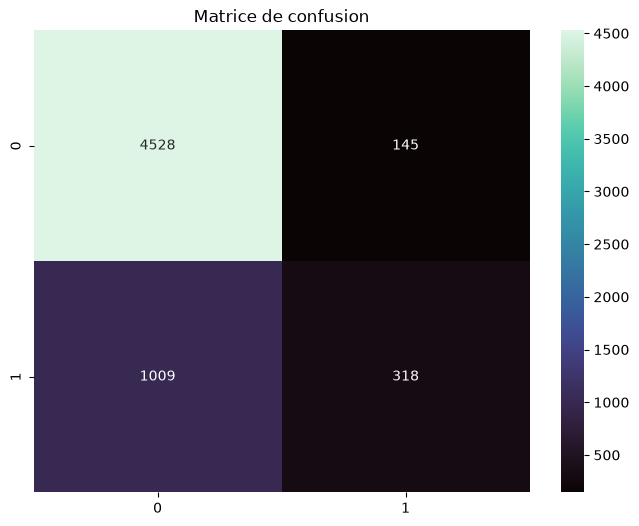

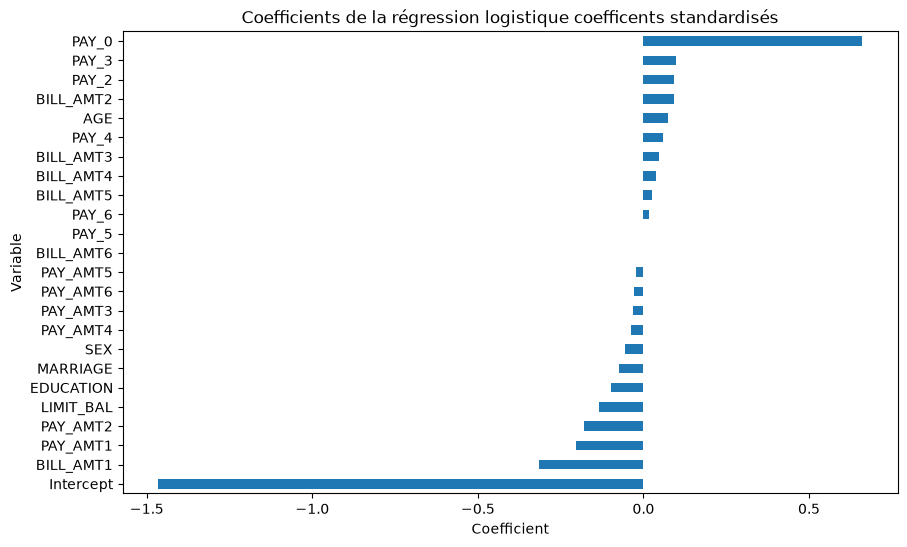

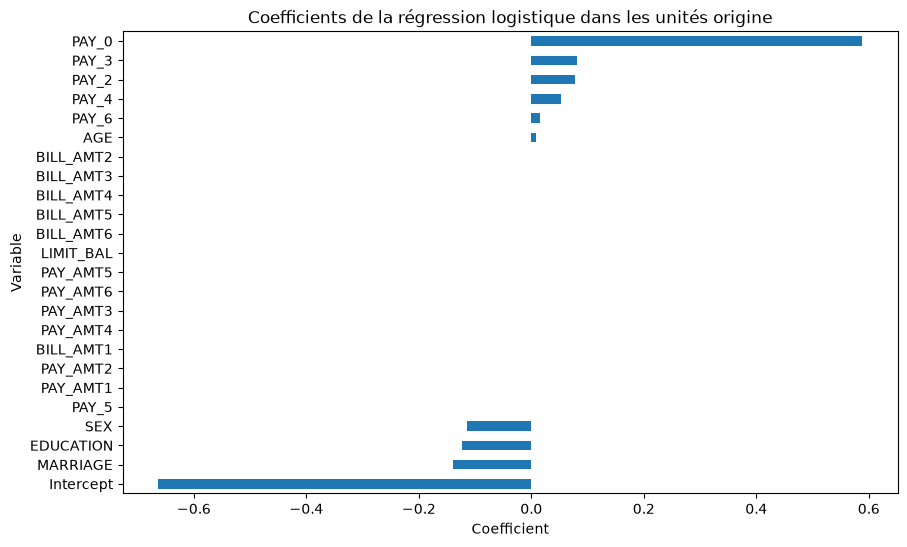

In [7]:
# Calculer l'accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy : {accuracy:.6f}')

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
print('Matrice de confusion :')
print(cm)

# Classification report
report = classification_report(y_test, y_pred, digits=4)
print('Classification report :')
print(report)

# Afficher la matrice de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='mako')
plt.title('Matrice de confusion')
plt.show()

# Afficher les coefficients
coefficients = model_logit.coef_
intercept = model_logit.intercept_

# Créer un dataframe
df_coeff = pd.DataFrame(coefficients, columns=X.columns)
df_coeff['Intercept'] = intercept

# Transposer le dataframe
df_coeff = df_coeff.T

# Renommer la colonne
df_coeff.columns = ['Coefficient']

# Afficher les coefficients
plt.figure(figsize=(10, 6))
df_coeff['Coefficient'].sort_values().plot(kind='barh')
plt.title('Coefficients de la régression logistique coefficents standardisés')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.show()


# Retour aux coefficients dans l'échelle originale
coef_original = coefficients / scaler.scale_
intercept_original = (
    intercept
    - np.sum(coef_std * scaler.mean_ / scaler.scale_)
)
# Créer un dataframe
df_coeff = pd.DataFrame(coef_original, columns=x_train_std.columns)
df_coeff['Intercept'] = intercept_original

# Transposer le dataframe
df_coeff = df_coeff.T

# Renommer la colonne
df_coeff.columns = ['Coefficient']

# Afficher les coefficients
plt.figure(figsize=(10, 6))
df_coeff['Coefficient'].sort_values().plot(kind='barh')
plt.title('Coefficients de la régression logistique dans les unités origine')
plt.xlabel('Coefficient')
plt.ylabel('Variable')
plt.show()

# Corrélation entre les variables

In [ ]:
import seaborn as sns
sns.clustermap(X.corr())

# Selection de variables avec statsmodels

In [ ]:
# Ajout de la constante
X_sm = sm.add_constant(X)

# Estimation du modèle
model = sm.Logit(y, X_sm)
result = model.fit()

# Afficher le résumé final
print(result.summary())

corr_matrix = X.corr().abs()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

# Variables à supprimer
to_drop = [
    col for col in upper.columns
    if any(upper[col] >= 0.9)
]

# Suppression
X_filtree= X.drop(columns=to_drop)

print("Variables supprimées :", to_drop)
print("Variables conservées :", X_filtree.columns.tolist())

# Arbre de decision

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree

clf = DecisionTreeClassifier(
    criterion='gini',              # Critère pour mesurer la qualité du split (gini ou entropy)
    splitter='best',               # Stratégie pour choisir le split (best ou random)
    max_depth=8,                   # Profondeur maximale de l'arbre : 8
    min_samples_split=2,           # Nombre minimum d'individu pour diviser un noeud
    min_samples_leaf=1,            # Nombre minimum d'individu dans une feuille
    min_weight_fraction_leaf=0.0,  # Fraction minimale de poids des échantillons dans une feuille
    max_features=None,             # Nombre maximum de caractéristiques à considérer pour un split
    random_state=42,               # Graine pour assurer la reproductibilité
    max_leaf_nodes=None,           # Nombre maximum de feuilles dans l'arbre
    min_impurity_decrease=0.0,     # Réduction minimale de l'impureté pour un split
    class_weight=None,             # Pondération des classes (None ou 'balanced')
    ccp_alpha=0.0                  # Paramètre de complexité pour l'élagage (post-pruning)
)

# Entraîner le modèle
clf.fit(x_train_std, y_train)

# Faire des prédictions sur l'ensemble de test
y_pred = clf.predict(x_test_std)

# Évaluer la performance de l'arbre de décision
acc_dtc = accuracy_score(y_test, y_pred)
dtc_conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, digits=4)

# Afficher les résultats
print(f'Accuracy: {acc_dtc}')
print('Confusion Matrix:')
print(dtc_conf_matrix)
print('Classification Report:')
print(class_report)

Accuracy: 0.8158333333333333
Confusion Matrix:
[[4409  264]
 [ 841  486]]
Classification Report:
              precision    recall  f1-score   support

           0     0.8398    0.9435    0.8886      4673
           1     0.6480    0.3662    0.4680      1327

    accuracy                         0.8158      6000
   macro avg     0.7439    0.6549    0.6783      6000
weighted avg     0.7974    0.8158    0.7956      6000



# performance en fonction de la profondeur et detection surraprentissage

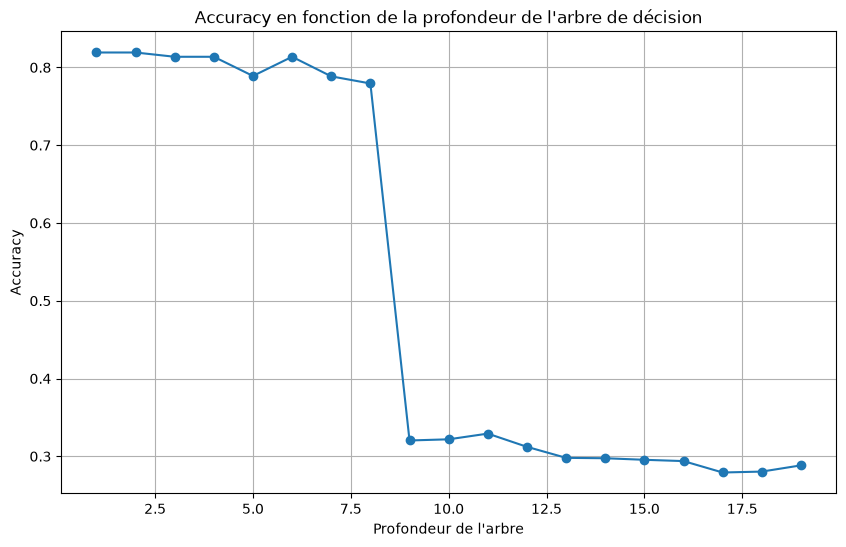

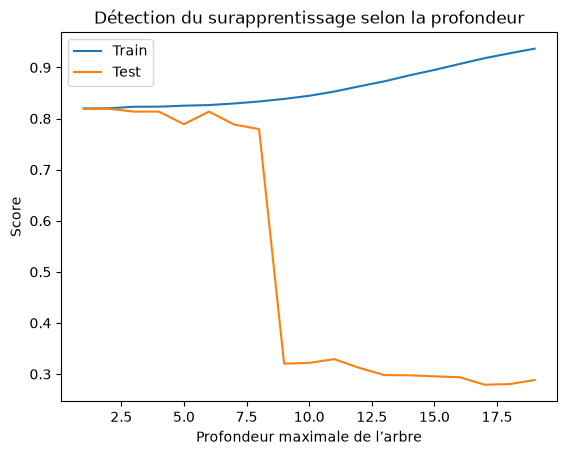

In [25]:
# Liste pour stocker les accuracy pour chaque profondeur
depths = range(1, 20)  # Par exemple, profondeur de 1 à 20
accuracies, train_scores, test_scores = [], [], []

for depth in depths:
    # Créer un modèle DecisionTreeClassifier avec la profondeur spécifiée
    clf = DecisionTreeClassifier(random_state=42, max_depth=depth)
    
    # Entraîner le modèle
    model = clf.fit(x_train_std, y_train)
    
    # Faire des prédictions sur l'ensemble de test
    y_pred = clf.predict(x_test)
    
    # Calculer l'accuracy et l'ajouter à la liste
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    train_scores.append(model.score(x_train_std, y_train))
    test_scores.append(model.score(x_test, y_test))
    

# Tracer l'accuracy en fonction de la profondeur de l'arbre
plt.figure(figsize=(10, 6))
plt.plot(depths, accuracies, marker='o')
plt.xlabel('Profondeur de l\'arbre')
plt.ylabel('Accuracy')
plt.title('Accuracy en fonction de la profondeur de l\'arbre de décision')
plt.grid(True)
plt.show()

# detection de surapprentissage
plt.plot(depths, train_scores, label='Train')
plt.plot(depths, test_scores, label='Test')
plt.xlabel('Profondeur maximale de l’arbre')
plt.ylabel('Score')
plt.legend()
plt.title("Détection du surapprentissage selon la profondeur")
plt.show()

# le score d’entraînement monte rapidement (proche de 1),
# le score de test atteint un plateau puis redescend ++ si > 8

# Validation croisée

In [30]:
from sklearn.model_selection import cross_validate

# Faire de la validation croisée avec kfolds : cv=5
scoring = ['accuracy', 'f1_macro']

clf_cv_results = cross_validate(
    estimator=clf,             # Modèle à évaluer
    X=x_train_std,             # Variables explicatives
    y=y_train,                 # Variable cible
    cv= 5,                     # Stratégie de validation croisée si un chiffre Kfolds
    scoring=['accuracy', 'f1_macro'],              # Métrique d'évaluation
    return_train_score=True,   # Conserve également les scores d'apprentissage
    n_jobs=-1                  # Nombre de processeurs utilisés (-1 = tous)
)

# Afficher les résultats pour chaque fold
print("Accuracy par fold :",
      [f"{x:.5f}" for x in clf_cv_results['test_accuracy']])

print("F1 Macro par fold :",
      [f"{x:.5f}" for x in clf_cv_results['test_f1_macro']])

# Moyennes et écart type 
print(
    "Accuracy : "
    f"{clf_cv_results['test_accuracy'].mean():.4f} "
    f"± {clf_cv_results['test_accuracy'].std():.4f}"
)

print(
    "F1 Macro : "
    f"{clf_cv_results['test_f1_macro'].mean():.4f} "
    f"± {clf_cv_results['test_f1_macro'].std():.4f}"
)

Accuracy par fold : ['0.81375', '0.82125', '0.81417', '0.81833', '0.81208']
F1 Macro par fold : ['0.67749', '0.68960', '0.67484', '0.68747', '0.66575']
Accuracy : 0.8159 ± 0.0034
F1 Macro : 0.6790 ± 0.0087


# Validation croisée stratifiée

In [36]:
from sklearn.model_selection import cross_validate, StratifiedKFold

# Validation croisée stratifiée à 5 folds
cvstrat = StratifiedKFold(
    n_splits=5,  # Nombre de plis (folds) de la validation croisée
    shuffle=True, # Mélange les observations avant de créer les plis
    random_state=42 # Graine pour assurer la reproductibilité
)

scoring = ['accuracy', 'f1_macro']

clf_cvstrat_results = cross_validate(
    estimator=clf,             # Modèle à évaluer
    X=x_train_std,             # Variables explicatives
    y=y_train,                 # Variable cible
    cv= cvstrat,               # Stratégie de validation croisée si un chiffre Kfolds
    scoring=['accuracy', 'f1_macro'],              # Métrique d'évaluation
    return_train_score=True,   # Conserve également les scores d'apprentissage
    n_jobs=-1                  # Nombre de processeurs utilisés (-1 = tous)
)

# Afficher les résultats pour chaque fold
print("Accuracy par fold :",
      [f"{x:.5f}" for x in clf_cvstrat_results['test_accuracy']])

print("F1 Macro par fold :",
      [f"{x:.5f}" for x in clf_cvstrat_results['test_f1_macro']])

# Moyennes et écart type 
print(
    "Accuracy : "
    f"{clf_cvstrat_results['test_accuracy'].mean():.4f} "
    f"± {clf_cvstrat_results['test_accuracy'].std():.4f}"
)

print(
    "F1 Macro : "
    f"{clf_cvstrat_results['test_f1_macro'].mean():.4f} "
    f"± {clf_cvstrat_results['test_f1_macro'].std():.4f}"
)

Accuracy par fold : ['0.82021', '0.81646', '0.81396', '0.81229', '0.81583']
F1 Macro par fold : ['0.68496', '0.67272', '0.67244', '0.66951', '0.67745']
Accuracy : 0.8157 ± 0.0027
F1 Macro : 0.6754 ± 0.0054


# Optimisation avec GridSearch()

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Meilleurs paramètres: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Score moyen (meilleur modèle) sur la validation croisée: 0.484115
Evaluation sur le jeu test
Accuracy: 0.81867
Recall: 0.36775
Precision: 0.66214
F1 Score: 0.47287
Temps d'exécution: 95.90436 secondes
Classification Report:
              precision    recall  f1-score   support

           0     0.8406    0.9467    0.8905      4673
           1     0.6621    0.3677    0.4729      1327

    accuracy                         0.8187      6000
   macro avg     0.7514    0.6572    0.6817      6000
weighted avg     0.8011    0.8187    0.7981      6000

Matrice de confusion:


array([[4424,  249],
       [ 839,  488]])

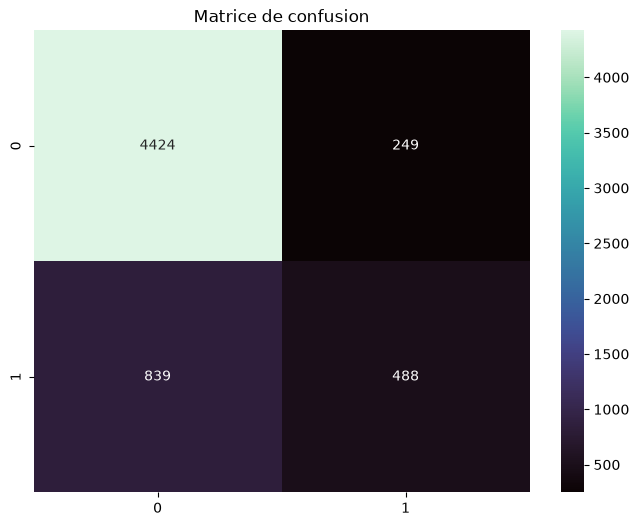

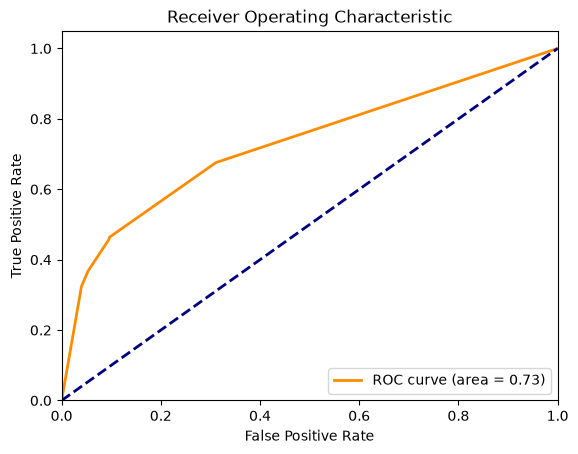

In [37]:
# Définir les paramètres à tester avec GridSearchCV
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3,4,5,6,7,8,9,10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4]
}

# Initialiser le modèle d'arbre de décision
dt = DecisionTreeClassifier(random_state=42)

# Mettre en place GridSearchCV
grid_search = GridSearchCV(estimator=dt, param_grid=param_grid, scoring='f1', cv=cvstrat, n_jobs=1, verbose=1)

# Enregistrer le temps d'exécution
start_time = time.time()

# Exécuter GridSearchCV
grid_search.fit(x_train_std, y_train)

# Enregistrer le temps d'exécution
execution_time_dt = time.time() - start_time

# Meilleurs paramètres
best_params = grid_search.best_params_
print("Meilleurs paramètres:", best_params)

# Score moyen du meilleur modèle (validation croisée)
mean_score_best_model = grid_search.best_score_
print(f"Score moyen (meilleur modèle) sur la validation croisée: {mean_score_best_model:.6f}")

# Prédictions avec le meilleur modèle
y_pred = grid_search.predict(x_test_std)

# Évaluation du modèle
print("Evaluation sur le jeu test")
accuracy_dt = accuracy_score(y_test, y_pred)
recall_dt = recall_score(y_test, y_pred)
precision_dt = precision_score(y_test, y_pred)
f1_dt = f1_score(y_test, y_pred)

# Afficher les résultats
print(f"Accuracy: {accuracy_dt:.5f}")
print(f"Recall: {recall_dt:.5f}")
print(f"Precision: {precision_dt:.5f}")
print(f"F1 Score: {f1_dt:.5f}")
print(f"Temps d'exécution: {execution_time_dt:.5f} secondes")
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

# Matrice de confusion
conf_matrix_dt = confusion_matrix(y_test, y_pred)
print("Matrice de confusion:")
display(conf_matrix_dt)

# Afficher la matrice de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_dt, annot=True, fmt='d', cmap='mako')
plt.title('Matrice de confusion')
plt.show()

# Courbe ROC pour évaluer le meilleur modèle
y_proba = grid_search.predict_proba(x_test_std)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Affichage de la courbe ROC
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# Random forest

Accuracy: 0.812667
Classification Report:
              precision    recall  f1-score   support

           0     0.8394    0.9392    0.8865      4673
           1     0.6316    0.3670    0.4643      1327

    accuracy                         0.8127      6000
   macro avg     0.7355    0.6531    0.6754      6000
weighted avg     0.7934    0.8127    0.7931      6000

Matrice de confusion:


array([[4389,  284],
       [ 840,  487]])

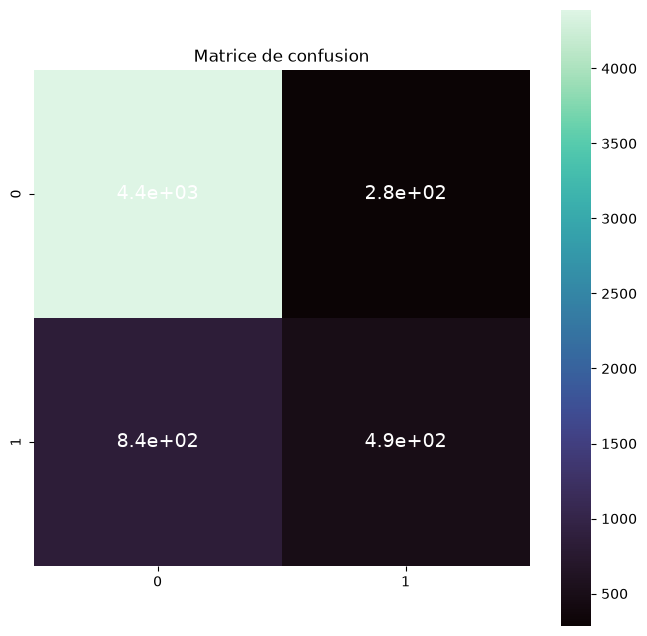

In [41]:
rf = RandomForestClassifier(
    n_estimators=200,               # Nombre d'arbres dans la forêt
    criterion='gini',               # Critère pour mesurer la qualité des splits (gini ou entropy)
    max_depth=None,                 # Profondeur maximale des arbres (None = pas de limite)
    min_samples_split=2,            # Nombre minimum d'échantillons pour diviser un noeud
    min_samples_leaf=1,             # Nombre minimum d'échantillons dans une feuille
    min_weight_fraction_leaf=0.0,   # Fraction minimale de poids des échantillons dans une feuille
    max_features='sqrt',            # Nombre max de caractéristiques pour chaque split (sqrt = racine carrée du total)
    max_leaf_nodes=None,            # Nombre maximum de feuilles par arbre (None = pas de limite)
    min_impurity_decrease=0.0,      # Réduction minimale de l'impureté pour effectuer un split
    bootstrap=True,                 # Si True, les échantillons sont tirés avec remplacement
    oob_score=False,                # Si True, utilise des échantillons hors sac pour évaluer la précision
    n_jobs=None,                    # Nombre de threads pour l'entraînement (-1 = utiliser tous les coeurs)
    random_state=42,                # Graine pour assurer la reproductibilité
    verbose=0,                      # Niveau de verbosité pendant l'entraînement (0 = silencieux)
    warm_start=False,               # Si True, réutilise la solution précédente pour ajouter plus d'estimateurs
    class_weight=None,              # Pondération des classes (None ou 'balanced')
    ccp_alpha=0.0,                  # Paramètre de complexité pour l'élagage (post-pruning)
    max_samples=None                # Nombre maximum d'échantillons à utiliser pour chaque arbre (None = tous)
)

# Entraîner le modèle
rf.fit(x_train_std, y_train.squeeze())

# Faire des prédictions sur l'ensemble de test
y_pred = rf.predict(x_test_std)

# Évaluer la performance du modèle Random Forest
acc_rfc = accuracy_score(y_test, y_pred)
rfc_conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, digits=4)

# Afficher les résultats
print(f'Accuracy: {acc_rfc:.6f}')
print('Classification Report:')
print(class_report)

# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de confusion:")
display(conf_matrix)

# Afficher la matrice de confusion
plt.figure(figsize=(8, 8))
sns.heatmap(rfc_conf_matrix, annot=True, cmap='mako', annot_kws={"color": "white", "size": 14}, square=True )
plt.title('Matrice de confusion')
plt.show()

# Validation croisée stratifiée du random forest

In [42]:
from sklearn.model_selection import cross_validate, StratifiedKFold

# Validation croisée stratifiée à 5 folds
cvstrat = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = ['accuracy', 'f1_macro']

rf_cv_results = cross_validate(
    rf,
    x_train_std,
    y_train.squeeze(),
    cv=cvstrat,
    scoring=scoring,
    return_train_score=True
)

# Afficher les résultats pour chaque fold
print("Accuracy par fold :",
      [f"{x:.5f}" for x in rf_cv_results['test_accuracy']])

print("F1 Macro par fold :",
      [f"{x:.5f}" for x in rf_cv_results['test_f1_macro']])

# Moyennes et écart type 
print(
    "Accuracy : "
    f"{rf_cv_results['test_accuracy'].mean():.5f} "
    f"± {rf_cv_results['test_accuracy'].std():.5f}"
)

print(
    "F1 Macro : "
    f"{rf_cv_results['test_f1_macro'].mean():.5f} "
    f"± {rf_cv_results['test_f1_macro'].std():.5f}"
)

Accuracy par fold : ['0.82208', '0.82125', '0.81688', '0.81708', '0.81563']
F1 Macro par fold : ['0.68810', '0.69019', '0.68155', '0.68296', '0.67938']
Accuracy : 0.81858 ± 0.00258
F1 Macro : 0.68444 ± 0.00406


# Optimisation des hyper parametres avec GridSearch()

Fitting 5 folds for each of 81 candidates, totalling 405 fits


/Users/nathanael/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/Users/nathanael/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/Users/nathanael/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/Users/nathanael/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change

Meilleurs paramètres: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 100}
Score moyen (meilleur modèle) sur la validation croisée: 0.4205
Résultats:
Accuracy: 0.81133
Recall: 0.28787
Precision: 0.67135
F1 Score: 0.40295
Temps d'exécution: 926.65547 secondes
Classification Report:
              precision    recall  f1-score   support

           0     0.8260    0.9600    0.8880      4673
           1     0.6714    0.2879    0.4030      1327

    accuracy                         0.8113      6000
   macro avg     0.7487    0.6239    0.6455      6000
weighted avg     0.7918    0.8113    0.7807      6000

Matrice de confusion:


array([[4486,  187],
       [ 945,  382]])

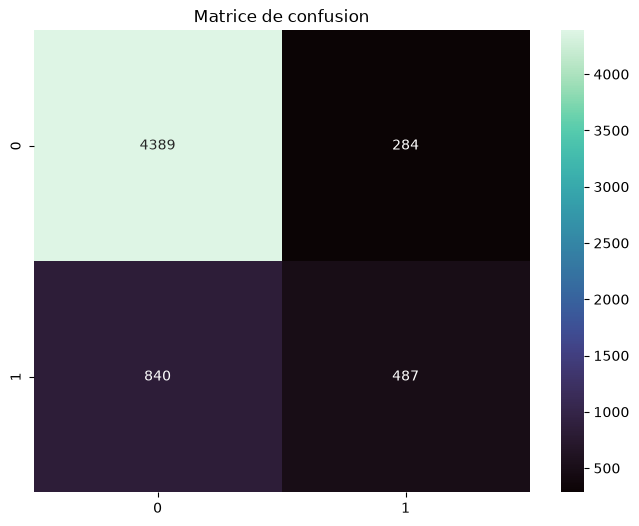

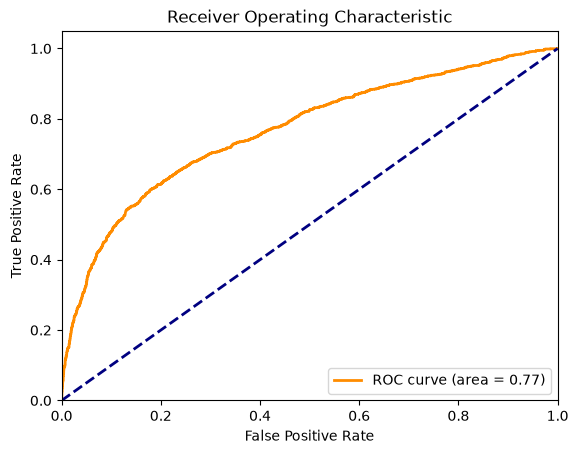

In [ ]:
# Définir les paramètres à tester avec GridSearchCV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 7],
    'min_samples_split': [10, 15],
    'min_samples_leaf': [4, 6],
}

# Mettre en place GridSearchCV
grid_search = GridSearchCV(
    estimator=rf, 
    param_grid=param_grid, 
    scoring='f1', 
    cv=cvstrat,
    return_train_score=True,
    n_jobs=1, 
    verbose=1)

# Enregistrer le temps d'exécution
start_time = time.time()

# Exécuter GridSearchCV
grid_search.fit(x_train_std, y_train.squeeze())

# Enregistrer le temps d'exécution
execution_time_rf = time.time() - start_time

# Meilleurs paramètres
best_params = grid_search.best_params_
print("Meilleurs paramètres:", best_params)

# Score moyen du meilleur modèle (validation croisée)
mean_score_best_model = grid_search.best_score_
print(f"Score moyen (meilleur modèle) sur la validation croisée: {mean_score_best_model:.4f}")

# Prédictions avec le meilleur modèle
y_pred = grid_search.predict(x_test_std)

# Évaluation du modèle
accuracy_rf = accuracy_score(y_test, y_pred)
recall_rf = recall_score(y_test, y_pred)
precision_rf = precision_score(y_test, y_pred)
f1_rf = f1_score(y_test, y_pred)

# Afficher les résultats
print("Résultats:")
print(f"Accuracy: {accuracy_rf:.5f}")
print(f"Recall: {recall_rf:.5f}")
print(f"Precision: {precision_rf:.5f}")
print(f"F1 Score: {f1_rf:.5f}")
print(f"Temps d'exécution: {execution_time_rf:.5f} secondes")
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

# Matrice de confusion
conf_matrix_rf = confusion_matrix(y_test, y_pred)
print("Matrice de confusion:")
display(conf_matrix_rf)

# Afficher la matrice de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(rfc_conf_matrix, annot=True, fmt='d', cmap='mako')
plt.title('Matrice de confusion')
plt.show()

# Courbe ROC
y_proba = grid_search.predict_proba(x_test_std)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Affichage de la courbe ROC
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()